This is part 1 of project 4

This is the code for the decision tree classifier (was NOT trained using fSize)

19020 events in total
13212 events with fSize < 3.0
class
g    8857
h    4355
Name: count, dtype: int64
Normal tree: train =  0.8008326237108525 test =  0.7771471812334468
Balanced tree: train =  0.7741508184312612 test =  0.7446083995459705


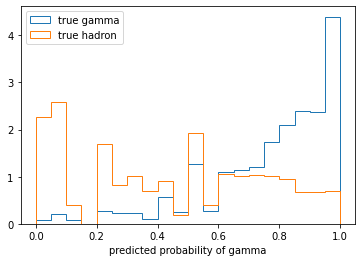

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_curve

names = ['index', 'fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
data = pd.read_csv('/Users/luisrojascastillo/Downloads/telescope_data.csv', names=names)
print(len(data), 'events in total')

# This is to keep only the low energy band
low = data[data['fSize'] < 3.0]
print(len(low), 'events with fSize < 3.0')
print(low['class'].value_counts())

# Features
features = ['fLength', 'fWidth', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist']
X = low[features].values

# Label: 1 = gamma (g), 0 = hadron (h)
z = (low['class'] == 'g').astype(int).values

# Training the decision tree
X_train, X_test, z_train, z_test = train_test_split(X, z, test_size=0.2, random_state=1)
tree_clf = DecisionTreeClassifier(max_depth=16, min_samples_leaf=64)
tree_clf_alt = DecisionTreeClassifier(max_depth=16, min_samples_leaf=64, class_weight='balanced')
tree_clf.fit(X_train, z_train)
tree_clf_alt.fit(X_train, z_train)

# This is for accuracy on the training and test data
print('Normal tree: train = ', accuracy_score(z_train, tree_clf.predict(X_train)), 'test = ', accuracy_score(z_test, tree_clf.predict(X_test)))
print('Balanced tree: train = ', accuracy_score(z_train, tree_clf_alt.predict(X_train)), 'test = ', accuracy_score(z_test, tree_clf_alt.predict(X_test)))

# For the probability that each test event is a gamma
z_pred = tree_clf.predict_proba(X_test)[:,1]

# Split by the true type
gamma_prob = z_pred[z_test==1]
hadron_prob = z_pred[z_test==0]

plt.hist(gamma_prob, bins=20, histtype='step', density=True, label='true gamma')
plt.hist(hadron_prob, bins=20, histtype='step', density=True, label='true hadron')
plt.xlabel('predicted probability of gamma')
plt.legend()
plt.show()


max_depth= 2 min_samples_leaf=  1 train=0.751 test=0.763
max_depth= 2 min_samples_leaf=  4 train=0.751 test=0.763
max_depth= 2 min_samples_leaf= 16 train=0.751 test=0.763
max_depth= 2 min_samples_leaf= 64 train=0.751 test=0.763
max_depth= 2 min_samples_leaf=256 train=0.746 test=0.756
max_depth= 4 min_samples_leaf=  1 train=0.770 test=0.764
max_depth= 4 min_samples_leaf=  4 train=0.770 test=0.764
max_depth= 4 min_samples_leaf= 16 train=0.770 test=0.764
max_depth= 4 min_samples_leaf= 64 train=0.769 test=0.764
max_depth= 4 min_samples_leaf=256 train=0.763 test=0.752
max_depth= 8 min_samples_leaf=  1 train=0.833 test=0.782
max_depth= 8 min_samples_leaf=  4 train=0.829 test=0.783
max_depth= 8 min_samples_leaf= 16 train=0.824 test=0.787
max_depth= 8 min_samples_leaf= 64 train=0.799 test=0.783
max_depth= 8 min_samples_leaf=256 train=0.772 test=0.759
max_depth=16 min_samples_leaf=  1 train=0.962 test=0.771
max_depth=16 min_samples_leaf=  4 train=0.915 test=0.771
max_depth=16 min_samples_leaf= 

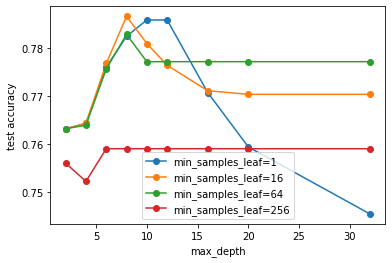

In [17]:
# Look at train vs test accuracy. If train >> test, then the tree is overfitting
for depth in [2,4,8,16,32]:
    for leaf in [1,4,16,64,256]:
        clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        clf.fit(X_train, z_train)
        train_acc = accuracy_score(z_train, clf.predict(X_train))
        test_acc = accuracy_score(z_test, clf.predict(X_test))
        print(f'max_depth={depth:2d} min_samples_leaf={leaf:3d} train={train_acc:.3f} test={test_acc:.3f}')

# Plot test accuracy vs max depth for few leaf sizes
depths = [2,4,6,8,10,12,16,20,32]
for leaf in [1,16,64,256]:
    test_acc = []
    for depth in depths:
        clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        clf.fit(X_train, z_train)
        test_acc.append(accuracy_score(z_test, clf.predict(X_test)))
    plt.plot(depths, test_acc, 'o-', label=f'min_samples_leaf={leaf}')
plt.xlabel('max_depth')
plt.ylabel('test accuracy')
plt.legend()
plt.show()

The first graph is saying that for each test event, the decision tree gives a probability that the event is a gamma. A true gamma, which is the blue plot, shows that most of them are pushed towards 1, which is good, but there is a long tail down to 0.4-0.6, and there are some near 0.
These are gammas the tree isn't sure about, or is wrong about them.

Then there are the true adrons, which shows them being spread out a bit more than the gammas, and the overlap is why the low-energy band is hard. In the moons example from class, the two histograms sat at opposite ends (near 0 and 1), whereas here, they share a lot of the middle, so some events will always be mixed up.

Now, the second graph is the test accuracy vs max_depth, where each line uses a different min_samples_leaf, which is the smallest number of events allowed at the end of a branch.

Small trees (which are max_depth 2-4) are too simple. All the lines are around 75-76%, which means that the true hasn't learned enough yet. For trees that have a max_depth 8-12 do the best, with the highest point around 79%. The blue line shows overfitting, because since there is no limit on leaf size, the deep tree memorizes the training data, which unfortunately doesn't carry over to new events.

We also see that Green (64) and orange (16) level off. The leaf-size limit stops the tree from growing any further, which keeps the overfitting in check: depth past about 12 doesn't change anything. The red line (min_samples_leaf=256) is too restrictive, but since every leaf must hold so many events that the tree can't learn the finer details,it gets stuck at about 76%.

This sounds almost like Goldilocks and the three bears.

Now we move on to part 2 of the project

Text(0.5, 0.98, 'Low energy band (fSize < 3.0): gamma rays vs cosmic rays')

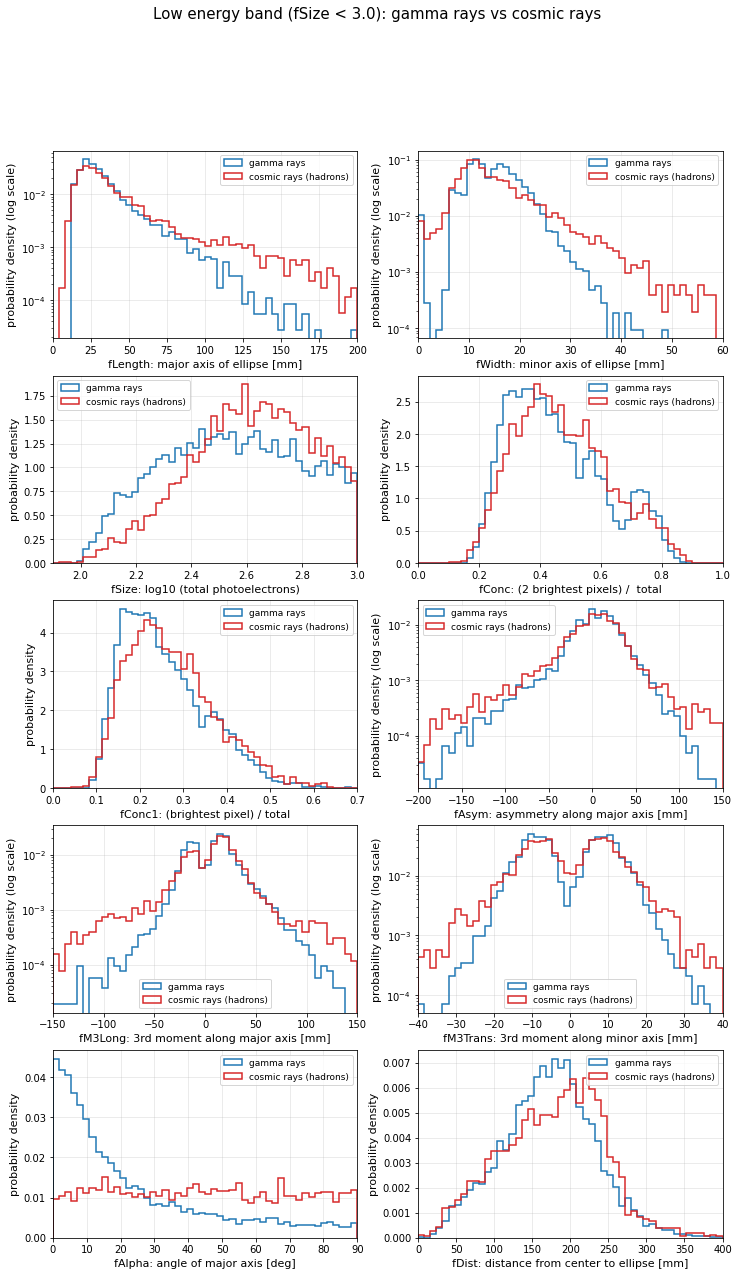

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

names = ['index', 'fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
data = pd.read_csv('/Users/luisrojascastillo/Downloads/telescope_data.csv', names=names)

# Keeping only the low energy band
low = data[data['fSize'] < 3.0]

# Splits the low energy events into gammas and cosmic rays (hadrons)
gammas = low[low['class'] == 'g']
hadrons = low[low['class'] == 'h']

plot_info = {'fLength': ('fLength: major axis of ellipse [mm]', (0, 200), True),
            'fWidth': ('fWidth: minor axis of ellipse [mm]', (0, 60), True),
            'fSize': ('fSize: log10 (total photoelectrons)', (1.9, 3.0), False),
            'fConc': ('fConc: (2 brightest pixels) /  total', (0, 1), False),
            'fConc1': ('fConc1: (brightest pixel) / total', (0, 0.7), False),
            'fAsym': ('fAsym: asymmetry along major axis [mm]', (-200, 150), True),
            'fM3Long': ('fM3Long: 3rd moment along major axis [mm]', (-150, 150), True),
            'fM3Trans': ('fM3Trans: 3rd moment along minor axis [mm]', (-40, 40), True),
            'fAlpha': ('fAlpha: angle of major axis [deg]', (0, 90), False),
            'fDist': ('fDist: distance from center to ellipse [mm]', (0, 400), False),
            }

fig, axes = plt.subplots(5, 2, figsize=(12, 20))
axes = axes.flatten()

for ax, (var, (label, xrange, use_log)) in zip(axes, plot_info.items()):
    bins = np.linspace(xrange[0], xrange[1], 51)

    # density = True makes each histogram have area 1, so they can be compared more easily
    ax.hist(gammas[var], bins=bins, density=True, histtype='step', linewidth=1.5, color='tab:blue', label='gamma rays')
    ax.hist(hadrons[var], bins=bins, density=True, histtype='step', linewidth=1.5, color='tab:red', label='cosmic rays (hadrons)')
    ax.set_xlim(xrange)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('probability density', fontsize=11)
    if use_log:
        ax.set_yscale('log')
        ax.set_ylabel('probability density (log scale)', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

fig.suptitle('Low energy band (fSize < 3.0): gamma rays vs cosmic rays', fontsize=15)



The line $\textbf{low = data[data[`fSize'] < 3.0]}$ keeps only the events with fSize below 3.0, and everything after that uses only these events. The plot_info also lists the names of all 10 variables, and the loop draws one plot for each.
The probability density function shows how likely each value is, and we estiamte it with a histogram, and then use density=True to scale it so the are under it is 1. 
The gamma rays and cosmic rays data is split into two respective groups, and each plot draws both groups on the same axes, with gammas in blue and cosmic rays in red. The histtype='step' draws just the outline instead of filled bars, so one histogram doesn't hide the other.

Okay, so what the code actually does is that it keeps the low-energy events (as explained before), splits the data up by type, sets up the plot settings, and then loops over the variables, making 50 equal-width bins across the chosen range, draws the gamma and cosmic-ray histograms on top of each other, and then sets the range, labels, and log scale if needed, as well as other required things for any graph.

It then finishes the figure by adding the overall title and any other miscallenous duties.

What we learn is that there is a strong difference in fAlpha, with the gammas bunching up at small angles, while cosmic rays are spread out evenly. For the smaller differences, we see that they are fLength, fWidth, and fM3Long, which differ primarily in their tails.

Moving on to part 3 of the project

Since the tree learns from one set and is graded on events it has never seen, if we graded it on its own training data, a deep enough tree would just memorize everything and then score perfectly, as shown in part 1. Basically, it would tell us nothing about how it performs when encountering new events.

In [24]:
# Features
features = ['fLength', 'fWidth', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist']
X = low[features].values
z = (low['class'] == 'g').astype(int).values

# For the 80% training, 20% sets
X_train, X_test, z_train, z_test = train_test_split(X, z, test_size=0.2, stratify=z, random_state=1)

print('Total low energy events:', len(z))
print('Training events:', len(z_train), f'({len(z_train)/len(z):.0%})')
print('Testing events:', len(z_test), f'({len(z_test)/len(z):.0%})')
print(f'Fraction of gammas - all data: {z.mean():.3f} training: {z_train.mean():.3f} test: {z_test.mean():.3f}')


Total low energy events: 13212
Training events: 10569 (80%)
Testing events: 2643 (20%)
Fraction of gammas - all data: 0.670 training: 0.670 test: 0.670


Now, for 10,569 events, this is more than enough information for the tree to actually learn. The 2,643 test events are still enough for a reliable score, which is about 79% accuracy, and the uncertainty is only about $\pm 0.8%$

The events are shuffled first, so both sets should be fair samples of the low-energy band. Additionally, there are about two gammas for every cosmic ray, and stratify=z keeps exactly 67% gammas in both sets.

Also, random_states=1 needs to be fixed. The split comes out the same for every run, so in that way, the results can be reproduced and different tree settings are compared on the same events.

Tree settings should be chosen using the training data, and the test set used once at the end, otherwise we'd end up tuning the tree to the test set. Additionally, fSize is left out, as it was used only to select the low-energy band, so it is in neither set.

The difference between this and part 1 is that part 1's split didn't use stratify=z, but this one does. 

Now, we move on to part 4 of the project

In [25]:
from sklearn.model_selection import cross_val_score

# Default settings
default_tree = DecisionTreeClassifier(random_state=1)
default_tree.fit(X_train, z_train)
print('Default tree: depth = ', default_tree.get_depth(), ' leaves = ', default_tree.get_n_leaves())
print('train accuracy = ', round(accuracy_score(z_train, default_tree.predict(X_train)), 3))
print('test accuracy =', round(accuracy_score(z_test, default_tree.predict(X_test)), 3))


Default tree: depth =  36  leaves =  1505
train accuracy =  1.0
test accuracy = 0.731


Okay, so this was just me testing out why the default settings for the decision tree didn't work. We see that there are 36 depths levels with over 1,500 leaves, and the decision tree scores 100% on training data, but only 73% on the test data, which is a symptom of overfitting.

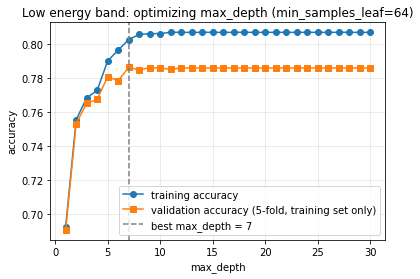

In [26]:
# Attempting to use max_depth from 1 to 30, with min_samples_leaf=64 sixed
depths = range(1, 31)
train_acc = []
valid_acc = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=64, random_state=1)
    scores = cross_val_score(tree, X_train, z_train, cv=5, scoring='accuracy')
    valid_acc.append(scores.mean())
    tree.fit(X_train, z_train)
    train_acc.append(accuracy_score(z_train, tree.predict(X_train)))

# Plotting the train and validation accuracy vs max_depth
best_depth = depths[np.argmax(valid_acc)]

plt.plot(depths, train_acc, 'o-', label='training accuracy')
plt.plot(depths, valid_acc, 's-', label='validation accuracy (5-fold, training set only)')
plt.axvline(best_depth, color='gray', linestyle='--', label=f'best max_depth = {best_depth}')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.title('Low energy band: optimizing max_depth (min_samples_leaf=64)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Okay, so then here, the code tries max_depth from 1 to 30, with min_samples_leaf=64 fixed at each time. It then picks the depth using only the training data, with cross_val_score splitting the training set into 5 parts, training it on 4, and checks on the 5th, and then repeats this whole process 5 times.
This gives a fair score on unseen events without touching the last set, which was outlined in part 3 of the project.

In [27]:
# Final tree
best_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=64, random_state=1)
best_tree.fit(X_train, z_train)
print('Optimized tree: max_depth =', best_depth)
print('train accuracy =', round(accuracy_score(z_train, best_tree.predict(X_train)), 3))
print('test accuracy =', round(accuracy_score(z_test, best_tree.predict(X_test)), 3))


Optimized tree: max_depth = 7
train accuracy = 0.802
test accuracy = 0.766


The final tree code is just built by using the best depth, and then checks it on the test set once.

I mean, from this, we see that the train accuracy and test accuracy scores are quite close, as compared to 100% and 73% by using the scikit-learn settings.

And now, part 5

max_depth= 1 leaves=  2 validation accuracy=0.691validation AUC=0.6942 test AUC=0.6597
max_depth= 2 leaves=  4 validation accuracy=0.753validation AUC=0.7424 test AUC=0.7009
max_depth= 3 leaves=  7 validation accuracy=0.765validation AUC=0.7732 test AUC=0.7309
max_depth= 4 leaves= 13 validation accuracy=0.767validation AUC=0.7922 test AUC=0.7550
max_depth= 5 leaves= 24 validation accuracy=0.781validation AUC=0.8065 test AUC=0.7752
max_depth= 6 leaves= 39 validation accuracy=0.778validation AUC=0.8137 test AUC=0.7943
max_depth= 7 leaves= 55 validation accuracy=0.786validation AUC=0.8187 test AUC=0.8028
max_depth= 8 leaves= 67 validation accuracy=0.785validation AUC=0.8214 test AUC=0.8053
max_depth= 9 leaves= 77 validation accuracy=0.786validation AUC=0.8243 test AUC=0.8093
max_depth=10 leaves= 86 validation accuracy=0.786validation AUC=0.8249 test AUC=0.8090
max_depth=11 leaves= 95 validation accuracy=0.785validation AUC=0.8235 test AUC=0.8069
max_depth=12 leaves=104 validation accuracy

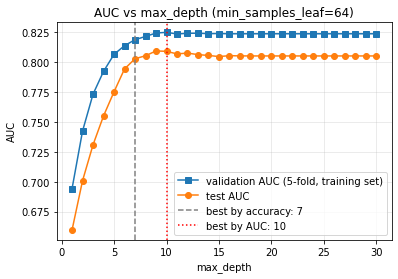

In [31]:
from sklearn.metrics import roc_auc_score, roc_curve

valid_auc = []
test_auc = []
n_leaves = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=64, random_state=1)

    # validation AUC
    valid_auc.append(cross_val_score(tree, X_train, z_train, cv=5, scoring='roc_auc').mean())

    # then test the AUC
    tree.fit(X_train, z_train)
    test_auc.append(roc_auc_score(z_test, tree.predict_proba(X_test)[:,1]))
    n_leaves.append(tree.get_n_leaves())

for depth, va, te, nl, acc in zip(depths, valid_auc, test_auc, n_leaves, valid_acc):
    print(f'max_depth={depth:2d} leaves={nl:3d} validation accuracy={acc:.3f}' f'validation AUC={va:.4f} test AUC={te:.4f}')

best_auc_depth = depths[np.argmax(valid_auc)]
print()
print('Optimal tree from part 4: max_depth =', best_depth,
    f' validation AUC = {valid_auc[best_depth-1]:.4f} test AUC = {test_auc[best_depth-1]:.4f}')
print('Highest validation AUC: max_depth =', best_auc_depth, f' validation AUC = {max(valid_auc):.4f} test AUC = {test_auc[best_auc_depth-1]:.4f}')

# Plotting
plt.plot(depths, valid_auc, 's-', label='validation AUC (5-fold, training set)')
plt.plot(depths, test_auc, 'o-', label='test AUC')
plt.axvline(best_depth, color='gray', linestyle='--', label=f'best by accuracy: {best_depth}')
plt.axvline(best_auc_depth, color='red', linestyle=':', label=f'best by AUC: {best_auc_depth}')
plt.xlabel('max_depth')
plt.ylabel('AUC')
plt.title('AUC vs max_depth (min_samples_leaf=64)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


What we can see, pretty much, is that from depths 1-6, the AUC rises fast, so a shallow tree is too simple: it can only make a few cuts, so it can't separate the two types well.
From depths 7-10, it keeps rising slowly, and then peaks at depth 10. This is key, as it shows the the AUC is not the highest at depth 7.
From depths 10-17, it dips ever so slightly, because the new leaves are small and start learning random noise in the training data, which doesn't help on new events (a little bit of overfitting).
For depths 18 and over, it's basically completely flat, because min_samples_leaf=64 won't let the decision tree split any further, so a bigger max_depth gives the exact same tree.

The code basically, for each depth, makes a tree with that depth limit and at least 64 events in each leaf.

The blue line only uses the training data, by cutting the data into 5 pieces, trains on 4, and then scores the AUC on the 5th. It then does that 5 times and averages the scores.

The orange line trains the tree on all of the training data, and then gets each test event's probability of being a gamma. roc_auc_score compares those probabilities with the true answers. The AUC needs the probabilities rather than just yes/no, which is why we use predict_proba here and not predict.

the n_leaves.append(tree.get_n_leaves()) records how big the tree it, and it shows that the tree stops growing after depth 18.

The best_auc_depth = depths[np.argmax(valid_auc)] part finds the depth with the highest blue-line AUC, which is 10.

Now we move on to part 6, which is to show the evidence that my optimized model is not over-trained.

I think it's relatively easy to tell that my optimized model is not over-trained because, when looking at how an over-trained model behaves, we look back at part 1 of the project, which compares different training accuracies.

Basically, min_samples_leaf=1 (blue line) is an overtrained model. The decision tree memorizes all of the data, but doesn't really "learn" from it, so whatever information it memorizes isn't carried on to future events.

Okay, in any case, the reason this is important is because it shows that the optimized model is not over-trained. The behavior of the plot never falls to 0, meaning that there is never any complete memorization of the information by the decision tree, which means that it "learns" as it processes the data more.

In [33]:
opt_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=64, random_state=1).fit(X_train, z_train)
default_tree = DecisionTreeClassifier(random_state=1).fit(X_train, z_train)

for name, tree in [('Optimized tree', opt_tree), ('Default tree', default_tree)]:
    prob_train = tree.predict_proba(X_train)[:,1]
    prob_test = tree.predict_proba(X_test)[:,1]
    acc_train = accuracy_score(z_train, tree.predict(X_train))
    acc_test = accuracy_score(z_test, tree.predict(X_test))
    auc_train = roc_auc_score(z_train, prob_train)
    auc_test = roc_auc_score(z_test, prob_test)
    print(name)
    print(f' accuracy: train = {acc_train:.3f} test = {acc_test:.3f} difference = {acc_train-acc_test:.3f}')
    print(f' AUC: train = {auc_train:.3f} test = {auc_test:.3f} difference = {auc_train-auc_test:.3f}')


Optimized tree
 accuracy: train = 0.802 test = 0.766 difference = 0.036
 AUC: train = 0.845 test = 0.803 difference = 0.043
Default tree
 accuracy: train = 1.000 test = 0.731 difference = 0.269
 AUC: train = 1.000 test = 0.698 difference = 0.302


From the numbers, I saw that pretty much everything was very close to each other, but never 100%, which means that the decision tree didn't just memorize them down and "learn" nothing.

Since new events get about the same probability as the training events, then it means that what the tree learned carried over.

I was also able to tell that the tree is not over-trained because, the validation accuracy never dropped, and in fact rose until depth 7, and then stays flat. As shown in part 1, if the tree were over-trained, then the graph would continue to go down.

Also, min_samples_leaf=64 limits memorizing, as every decision is based on at least 64 events, so a few unusual events can't drive it.

Now we move on to part 7, which is to plot the ROC curve for the optimized model.

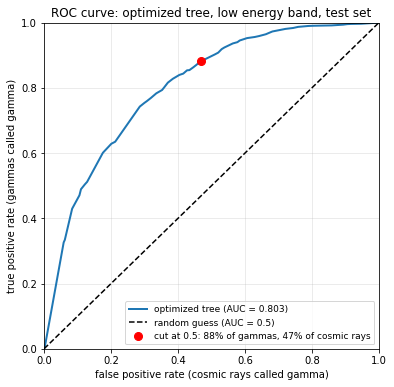

AUC = 0.803
 At the 0.5 cut: 88.1% of gammas are kept, 46.8% of cosmic rays get through


In [34]:
# Probability of gamma
prob_test = opt_tree.predict_proba(X_test)[:,1]

# roc_curve goes through every possible cut on that probability
fpr, tpr, cuts = roc_curve(z_test, prob_test)
auc = roc_auc_score(z_test, prob_test)

# Point that matches the normal 0.5 cut
pred = (prob_test > 0.5)
tpr_05 = pred[z_test == 1].mean()
fpr_05 = pred[z_test == 0].mean()

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, linewidth=2, label=f'optimized tree (AUC = {auc:.3f})')
plt.plot([0,1], [0,1], 'k--', label='random guess (AUC = 0.5)')
plt.plot(fpr_05, tpr_05, 'o', color='red', markersize=8, label=f'cut at 0.5: {tpr_05:.0%} of gammas, {fpr_05:.0%} of cosmic rays')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel('false positive rate (cosmic rays called gamma)')
plt.ylabel('true positive rate (gammas called gamma)')
plt.title('ROC curve: optimized tree, low energy band, test set')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.show()

print(f'AUC = {auc:.3f}')
print(f' At the 0.5 cut: {tpr_05:.1%} of gammas are kept, {fpr_05:.1%} of cosmic rays get through')


In the code, fpr is the fraction of cosmic rays called gamma, and tpr is the fraction of gammas called gamma. Then it takes the point that matches the normal 0.5 cut using the pred and tpr_05 and fpr_05 functions, and then plots everything.

The plot shows the optimized tree curve, which shows that each point is a different cut on the gamma probability. A strict cut lets in almost no cosmic rays, but keeps a few gammas. On the other hand, a loose cut keeps almost all gammas, but lets in most cosmic rays.

The random guess is the diagonal line. Since the optimized tree curve is well above it, the tree does tell the two types apart, with AUC = 0.803.

Now, the red dot is the normal 0.5 cut. It keeps 88% of gammas, but lets in 47% of cosmic rays. The tree leans toward saying "gamma" because there are about twice as many gammas.

Now, this isn't a perfect curve, as the optimized tree curve is well short of the top-left corner, which is primarily because gammas and cosmic rays overlap a lot in the low-energy band, as shown in part 2 of the project.

Okay, now for part 8 of the project, which is a question on what is important in the model

The five most important features are $\textbf{`fAlpha', `fLength', `fWidth', `fDist'} and \textbf{`fConc1'}$, with fAlpha being the most important. 

Why? Because fAlpha is responsible for spreading out the cosmic rays evenly, and piling up the gammas at small angles. The fLength feature is to account for cosmic ray showers that have a much longer tail than expected, and fWidth are for cosmic ray showers that tend to be wider in size.

fDist is primarily for the cosmic rays that lie a bit further from the camera center, and fConc1 is really just for fine-tuning splits.

If I had to redo the Decision Tree part, I would keep fAlpha, fLength, fWidth, fDist, and fConc1, and I'd also keep fM3Long, even though it is not AS important as the other five features.

Additionally, I would drop fConc, fAsym, fM3Trans, and fSize. I would drop fConc because it's practically identical to fConc1, and the decision tree really only needs one of them in order to work properly. The feature fAsym and fM3Trans are rarely used by the decision tree, and fSize is kept out due to the project requirements requiring it.

Okay, now here is the Multi-layer perceptron classifier part of the project

Since the first part of the project is just a reminder to continue using the low energy range, I just made sure that the cells that have the functions that do that are still running and good.

Now, for the second part of the project

Okay, so first I define a test set

In [38]:
# First had to introduce preprocessing so I can use StandardScaler later
from sklearn.preprocessing import StandardScaler

# Similar as the Decision Tree
X_rest, X_test, z_rest, z_test = train_test_split(X, z, test_size=0.20, stratify=z, random_state=1)


Then I split what was left (80% of events) into training and validation sets 

In [39]:
# 25% of the remaining 80% = 20% of all events
X_train, X_val, z_train, z_val = train_test_split(X_rest, z_rest, test_size=0.25, stratify=z_rest, random_state=1)


Then I made the pre-processing set

In [43]:
# Pre-processing
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print('Training: ', len(z_train), 'events fraction of gammas = ', round(z_train.mean(), 3))
print('Validation: ', len(z_val), 'events fraction of gammas = ', round(z_val.mean(), 3))
print('Test: ', len(z_test), 'events fraction of gammas =', round(z_test.mean(), 3))


Training:  7926 events fraction of gammas =  0.67
Validation:  2643 events fraction of gammas =  0.67
Test:  2643 events fraction of gammas = 0.67


I didn't have to print out the exact numbers, at elast I don't think, but I did so just so I would be able to look them up

Now, here is part 3 of the MLP part of the project, which is where I actually have to make the MLP model

Average (train): [ 0. -0.  0.  0. -0. -0. -0. -0.  0.]
Average (val): [ 0.    0.01  0.01  0.    0.02  0.   -0.03  0.03  0.03]
Average (test): [ 0.    0.04 -0.03 -0.02 -0.   -0.01 -0.01 -0.04 -0.  ]
Variance (train): [1. 1. 1. 1. 1. 1. 1. 1. 1.]
Variance (val): [0.96 1.01 1.01 1.02 0.99 1.   0.99 1.03 1.04]
Variance (test): [0.95 1.05 0.97 0.99 0.93 0.96 1.   0.95 1.03]


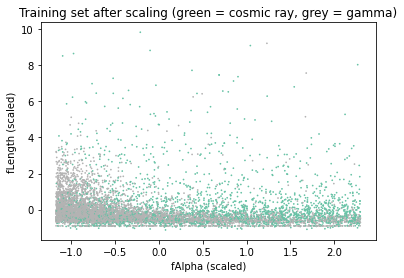

In [56]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)

X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


print('Average (train):', np.round(X_train.mean(axis=0), 2))
print('Average (val):', np.round(X_val.mean(axis=0), 2))
print('Average (test):', np.round(X_test.mean(axis=0), 2))
print('Variance (train):', np.round(X_train.var(axis=0), 2))
print('Variance (val):', np.round(X_val.var(axis=0), 2))
print('Variance (test):', np.round(X_test.var(axis=0), 2))

# Same plot as before
plt.scatter(X_train[:, features.index('fAlpha')], X_train[:, features.index('fLength')], s=0.5, c=z_train, cmap='Set2')
plt.xlabel('fAlpha (scaled)')
plt.ylabel('fLength (scaled)')
plt.title('Training set after scaling (green = cosmic ray, grey = gamma)')
plt.show()

Okay, so this part was very annoying, as I tried to speedrun and shorten it, and it ended up giving me absolutely horrible graphs, so I had to go back and actually make the scatter plots.

First, the code gets the data from the two sets from before, keeping only the low-energy ones, and then chooses the inputs.

After splitting the events into three groups, which are examined before, it then scales the inputs so every measurement has an average of 0 and a spread of 1. Without this, the network can't learn, and in fact, before debugging this, I kept on getting straight-line graphs that completely flattened after epoch 21.

epoch   1 training loss = 0.5380validation loss = 0.5250 validation accuracy = 0.7404
epoch   2 training loss = 0.5195validation loss = 0.5068 validation accuracy = 0.7537
epoch   3 training loss = 0.5069validation loss = 0.4940 validation accuracy = 0.7734
epoch   4 training loss = 0.4984validation loss = 0.4842 validation accuracy = 0.7809
epoch   5 training loss = 0.4925validation loss = 0.4764 validation accuracy = 0.7862
epoch   6 training loss = 0.4882validation loss = 0.4703 validation accuracy = 0.7911
epoch   7 training loss = 0.4854validation loss = 0.4659 validation accuracy = 0.7938
epoch   8 training loss = 0.4835validation loss = 0.4631 validation accuracy = 0.7953
epoch   9 training loss = 0.4823validation loss = 0.4613 validation accuracy = 0.7927
epoch  10 training loss = 0.4814validation loss = 0.4601 validation accuracy = 0.7896
epoch  11 training loss = 0.4808validation loss = 0.4592 validation accuracy = 0.7919
epoch  12 training loss = 0.4803validation loss = 0.45

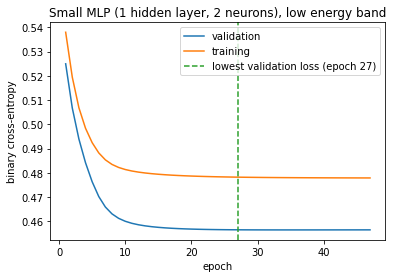

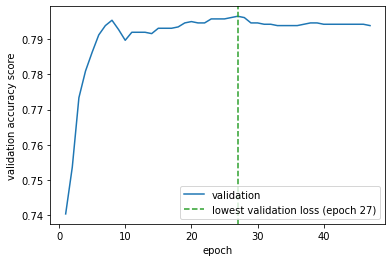

In [57]:
import copy
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

clf = MLPClassifier(solver='sgd',
                    batch_size=32,
                    activation="tanh",
                    learning_rate='constant',
                    learning_rate_init=0.01,
                    shuffle=True,
                    max_iter=200,
                    alpha=1e-3,
                    hidden_layer_sizes=(2,),
                    random_state=1,
                    early_stopping=False,
                    )

epochs = 300
patience = 20
tol = 1e-3

train_loss, val_loss, val_acc = [], [], []
best_val, best_epoch, best_clf = np.inf, -1, None
for epoch in range(epochs):
    clf.partial_fit(X_train, z_train, classes=[0,1])
    train_loss.append(log_loss(z_train, clf.predict_proba(X_train)[:,1]))
    val_loss.append(log_loss(z_val, clf.predict_proba(X_val)[:, 1]))
    val_acc.append(accuracy_score(z_val, clf.predict(X_val)))
    print(f"epoch {epoch + 1:3d} training loss = {train_loss[-1]:.4f}"
            f"validation loss = {val_loss[-1]:.4f} validation accuracy = {val_acc[-1]:.4f}")
    
    if val_loss[-1] < best_val - tol:
        best_val, best_epoch = val_loss[-1], epoch
        best_clf = copy.deepcopy(clf) 
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Stopping after epoch {epoch + 1}: no improvement larger than {tol}"
                    f"in the last {patience} epochs.")
            break

# The chosen network is the copy from the best epoch
print(f"best epoch (from validation): {best_epoch + 1}")
print(f"validation loss at that epoch: {best_val:.4f}")
print(f"validation accuracy at that epoch: {val_acc[best_epoch]:.3f}")
print(f"validation AUC at that epoch: {roc_auc_score(z_val, best_clf.predict_proba(X_val)[:,1]):.3f}")

# These are the loss curves
plt.plot(np.arange(1, np.size(val_loss) + 1), val_loss, label="validation")
plt.plot(np.arange(1, np.size(train_loss) + 1), train_loss, label="training")
plt.axvline(best_epoch + 1, color="C2", ls="--", label=f"lowest validation loss (epoch {best_epoch + 1})")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.title("Small MLP (1 hidden layer, 2 neurons), low energy band")
plt.legend()
plt.show()

# validation accuracy per epoch
plt.plot(np.arange(1, np.size(val_acc) + 1), val_acc, label="validation")
plt.axvline(best_epoch + 1, color="C2", ls="--", label=f"lowest validation loss (epoch {best_epoch + 1})")
plt.xlabel("epoch")
plt.ylabel("validation accuracy score")
plt.legend()
plt.show()

The code then builds the network, where the output is the network's probability that an event is a gamma, and then adjusts its weights a little at a time to make that probability be closer to the actually right answer.

It trains one epoch at a time, that's where the $\text{for epoch in range(epochs)}$ comes into play, where one epoch is one pass through all 7926 training events.

The code then checks the loss after every epoch, which is just a score of how wrong the probabilities are.

After that, the code then decides when to stop, and a real improvement would mean that the validation loss had dropped more than 0.001. Each time that happens, the code saves a copy of the network. It stops if 20 epochs in a row pass without any real improvement, because the network isn't learning anything anymore.

The first graph shows the loss vs epoch, where the x-axis is the epoch number, and the y-axis is the loss.

The orange line is how wrong the network is on the events that it learns from, and the blue line is how wrong it is on events that it has never learned from (this is the one that is more important).

What we can tell is that from epochs 1-10, the network is learning quicky and rapidly, as the loss drops from about 0.53 to less than 0.46. After that, from epochs 10-27, there are small improvements, but it decreases past epoch 27 (hence why the "best epoch" is 27). There is no over-training because the blue curve never goes back up.

For the second graph, it is a validation accuracy vs epoch graph, where the y-axis is the fraction of validation events classified correctly.

What we see is that the accuracy jumps from about 74% to 79% in the first 8 epochs, and after that, it only wiggles a little, between 79.0% and 79.6%, as a few events cross the 0.5 cut back and forth.

The best epoch is at 27 because it's at 79.6%, which is at the top of the curve.

Basically, at the end of the day, I saw that the small network was trained properly, stopped at a sensible point, and isn't over-trained. It gets about 80% of the validation events right, slightly better than the optimized decision tree, with just 2 hidden neurons.

Now here is part 4 of the MLP part of the project

Stopping after epoch 47
best epoch: 27
validation loss at best epoch: 0.4566
test loss at best epoch: 0.4981


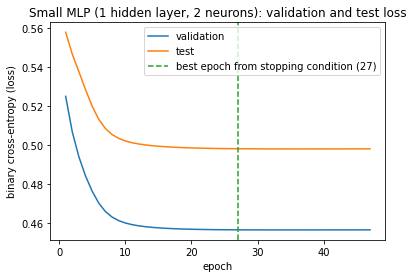

In [60]:
# Just rewriting the MLP neural network and then including the validation and testing loss functions
clf4 = MLPClassifier(solver='sgd',
                    batch_size=32,
                    activation="tanh",
                    learning_rate='constant',
                    learning_rate_init=0.01,
                    shuffle=True,
                    max_iter=200,
                    alpha=1e-3,
                    hidden_layer_sizes=(2,),
                    random_state=1,
                    early_stopping=False)

val_loss4, test_loss4 = [], []
best_val4, best_epoch4 = np.inf, -1
epochs_without_improvement = 0

for epoch in range(epochs):
    clf4.partial_fit(X_train, z_train, classes=[0,1])
    val_loss4.append(log_loss(z_val, clf4.predict_proba(X_val)[:,1]))
    test_loss4.append(log_loss(z_test, clf4.predict_proba(X_test)[:,1]))
    if val_loss4[-1] < best_val4 - tol:
        best_val4, best_epoch4 = val_loss4[-1], epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Stopping after epoch {epoch + 1}")
            break

print(f"best epoch: {best_epoch4 + 1}")
print(f"validation loss at best epoch: {val_loss4[best_epoch4]:.4f}")
print(f"test loss at best epoch: {test_loss4[best_epoch4]:.4f}")

# Plotting
epoch_numbers = np.arange(1, len(val_loss4) + 1)

plt.plot(epoch_numbers, val_loss4, label="validation")
plt.plot(epoch_numbers, test_loss4, label="test")
plt.axvline(best_epoch4 + 1, color="C2", ls="--", label=f"best epoch from stopping condition ({best_epoch4 + 1})")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy (loss)")
plt.title("Small MLP (1 hidden layer, 2 neurons): validation and test loss")
plt.legend()
plt.show()

The code simply retrains the neural network again, and because random_state = 1 is the same, it starts from the same weights and shuffles the events in the same way as it did in part 3. 

The empty lists were so that each epoch could add one number to each list, and best_val4 = np.inf means the "best score so far is infinitely bad", so the first epoch is always an improvement.

Then the code runs the training loop one epoch at a time. First through partial_fit, which makes one pass through all 7926 training events in groups of 32, nudging the weights each time, scores on the validation by computing the loss on the validation set and adding to to val_loss4, and then computs the loss on the test set and adds it to test_loss4. This number is the only one written down.

The plot, therefore, draws the validation lsos and the test loss against the epoch number. The green dashed line marks the best epoch, where the +1 in best_epoch + 1 is there because Python starts at 0.

The blue line (validation) says how wrong the network is on the events used to decide when to stop, the orange line (test) says how wrong it is on events that played no part in any decision, and the green dashed line is the best epoch (as stated before), which is chosen from the validation loss only.

It's pretty clear that the network is too small because the loss gets suck at about 0.46-0.50, and more epochs wouldn't lower it. Since there are only 2 hidden neurons, the network doesn't have enough "room" to learn the more complicated differences between gamma rays and cosmic rays. This is called "under fitting", which means that the model is too small, too simple, and a bigger network is needed in order to push the loss lower.

Now, here is part 5 of the MLP part of the project

In [61]:
def train_mlp(n_neurons, seed=1):
    clf = MLPClassifier(solver='sgd', batch_size=32, activation="tanh", learning_rate="constant", learning_rate_init=0.01, shuffle=True, max_iter=200, alpha=1e-3, hidden_layer_sizes=(n_neurons,), random_state=seed, early_stopping=False)
    train_loss, val_loss = [], []
    best_val, best_epoch, best_clf = np.inf, -1, None
    epochs_without_improvement = 0

    for epoch in range(300):
        clf.partial_fit(X_train, z_train, classes=[0,1])
        train_loss.append(log_loss(z_train, clf.predict_proba(X_train)[:,1]))
        val_loss.append(log_loss(z_val, clf.predict_proba(X_val)[:,1]))

        if val_loss[-1] < best_val - 1e-3:
            best_val, best_epoch = val_loss[-1], epoch
            best_clf = copy.deepcopy(clf)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= 20:
                break
    return best_clf, best_epoch, train_loss, val_loss


neuron_list = [1,2,4,8,16,32,64,128,256]
scan_train_loss, scan_val_loss, scan_val_acc, scan_val_auc = [], [], [], []

for n in neuron_list:
    net, best_ep, tr_loss, v_loss = train_mlp(n)
    scan_train_loss.append(tr_loss[best_ep])
    scan_val_loss.append(v_loss[best_ep])
    scan_val_acc.append(accuracy_score(z_val, net.predict(X_val)))
    scan_val_auc.append(roc_auc_score(z_val, net.predict_proba(X_val)[:,1]))
    print(f"{n:4f} neurons: best epoch {best_ep + 1:3d} training loss {tr_loss[best_ep]:.4f}" f"validation loss {v_loss[best_ep]:.4f} validation accuracy {scan_val_acc[-1]:.3f}" f"validation AUC {scan_val_auc[-1]:.3f}")
    

1.000000 neurons: best epoch  15 training loss 0.5250validation loss 0.5086 validation accuracy 0.754validation AUC 0.793
2.000000 neurons: best epoch  27 training loss 0.4782validation loss 0.4566 validation accuracy 0.796validation AUC 0.832
4.000000 neurons: best epoch  13 training loss 0.4660validation loss 0.4463 validation accuracy 0.805validation AUC 0.841
8.000000 neurons: best epoch  48 training loss 0.4431validation loss 0.4410 validation accuracy 0.798validation AUC 0.844
16.000000 neurons: best epoch  16 training loss 0.4435validation loss 0.4417 validation accuracy 0.799validation AUC 0.845
32.000000 neurons: best epoch  32 training loss 0.4290validation loss 0.4332 validation accuracy 0.803validation AUC 0.851
64.000000 neurons: best epoch  43 training loss 0.4185validation loss 0.4312 validation accuracy 0.800validation AUC 0.852
128.000000 neurons: best epoch  42 training loss 0.4223validation loss 0.4340 validation accuracy 0.800validation AUC 0.852
256.000000 neurons:

From what is shown, each time more neurons are added, the losses (training loss and validation loss) decrease, which is expected behavior.

I then decided to make the graphs for the loss, accuracy, and AUC against the number of neurons, the 5 random starts, and the loss curve of the optimized 32-neuron network.

The "for n in neuron_list:" part of the code trains the 9 networks, from tiny (1 neuron) to big (256 neurons), and then records, for each one, at its best epoch (training + validation loss, validation accuracy, and validation AUC).

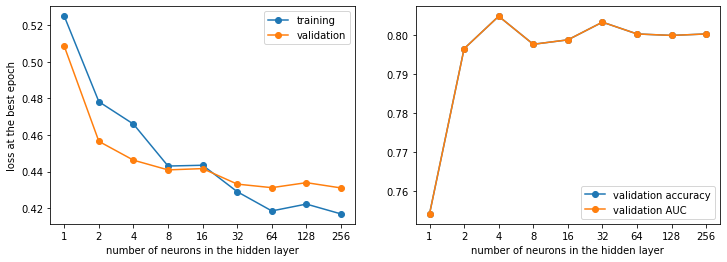

In [63]:
# loss, accuracy, and AUC against the number of neurons

fig, ax = plt.subplots(1, 2, figsize=(12,4))

# Training and validation loss at the best epoch
ax[0].plot(neuron_list, scan_train_loss, 'o-', label='training')
ax[0].plot(neuron_list, scan_val_loss, 'o-', label='validation')
ax[0].set_xscale('log', base=2)
ax[0].set_xticks(neuron_list)
ax[0].set_xticklabels(neuron_list)
ax[0].set_xlabel('number of neurons in the hidden layer')
ax[0].set_ylabel('loss at the best epoch')
ax[0].legend()

# validation accuracy and AUC
ax[1].plot(neuron_list, scan_val_acc, 'o-', label='validation accuracy')
ax[1].plot(neuron_list, scan_val_acc, 'o-', label='validation AUC')
ax[1].set_xscale('log', base=2)
ax[1].set_xticks(neuron_list)
ax[1].set_xticklabels(neuron_list)
ax[1].set_xlabel('number of neurons in the hidden layer')
ax[1].legend()
plt.show()

The code here merely draws the recorded numbers against the number of neurons.

4.0000 neurons: validation loss 0.4476 +- 0.0078 training loss 0.4600
8.0000 neurons: validation loss 0.4418 +- 0.0020 training loss 0.4420
16.0000 neurons: validation loss 0.4395 +- 0.0038 training loss 0.4335
32.0000 neurons: validation loss 0.4345 +- 0.0034 training loss 0.4244
64.0000 neurons: validation loss 0.4377 +- 0.0058 training loss 0.4260
128.0000 neurons: validation loss 0.4392 +- 0.0059 training loss 0.4245
256.0000 neurons: validation loss 0.4364 +- 0.0067 training loss 0.4221


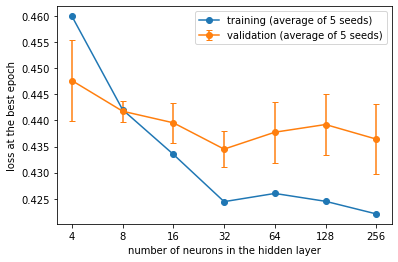

In [64]:
seed_neurons = [4, 8, 16, 32, 64, 128, 256]
mean_val, std_val, mean_train = [], [], []

for n in seed_neurons:
    v, t = [], []
    for seed in range(1, 6):
        net, best_ep, tr_loss, v_loss = train_mlp(n, seed)
        v.append(v_loss[best_ep])
        t.append(tr_loss[best_ep])
    mean_val.append(np.mean(v))
    std_val.append(np.std(v))
    mean_train.append(np.mean(t))
    print(f"{n:.4f} neurons: validation loss {np.mean(v):.4f} +- {np.std(v):.4f} training loss {np.mean(t):.4f}")

plt.errorbar(seed_neurons, mean_val, yerr=std_val, fmt='o-', capsize=3, color='C1', label='validation (average of 5 seeds)')
plt.plot(seed_neurons, mean_train, 'o-', color='C0', label='training (average of 5 seeds)')
plt.xscale('log', base=2)
plt.xticks(seed_neurons, seed_neurons)
plt.xlabel('number of neurons in the hidden layer')
plt.ylabel('loss at the best epoch')
plt.legend()
plt.show()

Now, here, there is a problem in that every training run depends a little on "luck", meaning that there is a  random starting weights and random shuffling events. At 32 neurons and up, the scan's results differ by only 0.002, which is too small to know whether one network is really better or just got lucky.

The code trains each network size 5 times, with random_state = 1,2,3,4, and 5. 

It then computes the average validation loss, the standard deviation, and the average training loss.

optimized MLP: 32 neurons, best epoch 32, stopped after epoch 52
validation loss 0.4332validation accuracy 0.803validation AUC 0.851


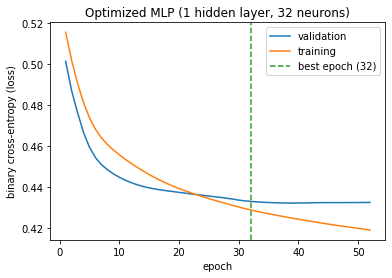

In [65]:
n_best = 32
best_mlp, best_epoch_opt, train_loss_opt, val_loss_opt = train_mlp(n_best)

print(f"optimized MLP: {n_best} neurons, best epoch {best_epoch_opt + 1}, stopped after epoch {len(val_loss_opt)}")
print(f"validation loss {val_loss_opt[best_epoch_opt]:.4f}" f"validation accuracy {accuracy_score(z_val, best_mlp.predict(X_val)):.3f}" f"validation AUC {roc_auc_score(z_val, best_mlp.predict_proba(X_val)[:,1]):.3f}")

plt.plot(np.arange(1, len(val_loss_opt) + 1), val_loss_opt, label='validation')
plt.plot(np.arange(1, len(train_loss_opt) + 1), train_loss_opt, label='training')
plt.axvline(best_epoch_opt + 1, color='C2', ls='--', label=f'best epoch ({best_epoch_opt + 1})')
plt.xlabel('epoch')
plt.ylabel('binary cross-entropy (loss)')
plt.title(f'Optimized MLP (1 hidden layer, {n_best} neurons)')
plt.legend()
plt.show()

Okay, then for this last piece of code, first it trains the chosen network (with 32 neurons, random_state=1) and saves it as best_mlp. It then prints the network's scores, and then plots the loss curve, epoch by epoch.

Okay, now we move to part 6 of the MLP project

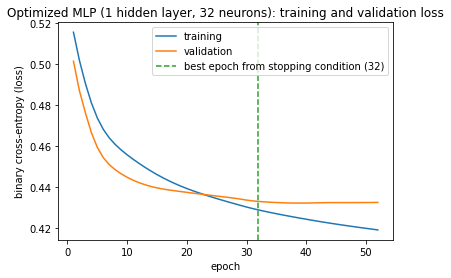

best epoch: 32 (training stopped after epoch 52)
training loss at best epoch: 0.4290
validation loss at best epoch: 0.4332


In [68]:
epoch_numbers = np.arange(1, len(val_loss_opt) + 1)

plt.plot(epoch_numbers, train_loss_opt, label='training')
plt.plot(epoch_numbers, val_loss_opt, label='validation')
plt.axvline(best_epoch_opt + 1, color='C2', ls='--', label=f'best epoch from stopping condition ({best_epoch_opt + 1})')
plt.xlabel('epoch')
plt.ylabel('binary cross-entropy (loss)')
plt.title(f'Optimized MLP (1 hidden layer, {n_best} neurons): training and validation loss')
plt.legend()
plt.show()

print(f"best epoch: {best_epoch_opt + 1} (training stopped after epoch {len(val_loss_opt)})")
print(f"training loss at best epoch: {train_loss_opt[best_epoch_opt]:.4f}")
print(f"validation loss at best epoch: {val_loss_opt[best_epoch_opt]:.4f}")


This is just plotting of the validation and train loss function as a function of the epoch number.

Now, we move on to part 7 of the MLP part of the project, which was calculating the loss function for the test data

In [69]:
p_small = best_clf.predict_proba(X_test)[:,1] # small MLP
p_opt = best_mlp.predict_proba(X_test)[:,1] # optimized MLP

test_loss_small = log_loss(z_test, p_small)
test_loss_opt = log_loss(z_test, p_opt)

print(f"small MLP (2 neurons, epoch {best_epoch + 1}): test loss = {test_loss_small:.4f}" f"test accuracy = {accuracy_score(z_test, best_clf.predict(X_test)):.3f} test AUC = {roc_auc_score(z_test, p_small):.3f}")
print(f"optimized MLP (32 neurons, epoch {best_epoch_opt + 1}): test loss = {test_loss_opt:.4f}" f"test accuracy = {accuracy_score(z_test, best_mlp.predict(X_test)):.3f} test AUC = {roc_auc_score(z_test, p_opt):.3f}")
print(f"difference in test loss (small - optimized) = {test_loss_small - test_loss_opt:.4f}")


small MLP (2 neurons, epoch 27): test loss = 0.4981test accuracy = 0.773 test AUC = 0.792
optimized MLP (32 neurons, epoch 32): test loss = 0.4655test accuracy = 0.788 test AUC = 0.828
difference in test loss (small - optimized) = 0.0327


Okay, so here, the loss measures how far the network's probabilities are from the truth, and the lower the loss, the better the network is performing. A lower test loss means that, on events the network has not seen yet, the optimized MLP is more confident when it's right and less confident when it's wrong. 

Also, in comparison with before, 2 neurons is too simple to describe the difference between gamma rays and cosmic rays, but with 32 neurons, the network can learn more detailed patterns, so the loss, the accuracy, and the AUC all improve.

Additionally, the code here also confirms the choice in part 5: on the validation set, the improvement was 0.023, and there is a similar improvement on the test set, which was never used for any decision. Therefore, choosing 32 neurons wasn't just fitted to the validation events.

Both test losses are higher than their validation losses, as shown in the 0.498 vs 0.457 for the small MLP, and 0.466 vs 0.433 for the optimized one. 
As in part 4, the test events are just a slightly harder random sample that affects both networks the same way, so the comparison is still valid. Against the decision tree on the same test events (accuracy 0.766, AUC 0.803), the optimized MLP is the best model by far.

Now this is for part 8 of the MLP part of the project

In [70]:
fpr_small, tpr_small, cuts_small = roc_curve(z_test, p_small)
fpr_opt, tpr_opt, cuts_opt = roc_curve(z_test, p_opt)

auc_small = roc_auc_score(z_test, p_small)
auc_opt = roc_auc_score(z_test, p_opt)

Here, roc_curve tries every possible cut on the probability. For each cut, it records the fraction of gamma rays kept and the fraction of cosmic rays let through.

In [73]:
# Trees don't need scaled inputs, so we have to redo the 80/20 split on the unscaled data
X_train_tree, X_test_tree, z_train_tree, z_test_tree = train_test_split(X, z, test_size=0.20, stratify=z, random_state=1)

from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=7, min_samples_leaf=64, random_state=1)
tree.fit(X_train_tree, z_train_tree)

p_tree = tree.predict_proba(X_test_tree)[:,1]
fpr_tree, tpr_tree, cuts_tree = roc_curve(z_test_tree, p_tree)
auc_tree = roc_auc_score(z_test_tree, p_tree)

print('Same test events as the MLPs?', np.array_equal(z_test_tree, z_test))
print(f"Area under the ROC curve (test set) = decision tree (max_depth=7) AUC = {auc_tree:.3f}")
print(f"small MLP (2 neurons) AUC = {auc_small:.3f} ")
print(f"optimized MLP (32 neurons) AUC = {auc_opt:.3f}")

Same test events as the MLPs? True
Area under the ROC curve (test set) = decision tree (max_depth=7) AUC = 0.803
small MLP (2 neurons) AUC = 0.792 
optimized MLP (32 neurons) AUC = 0.828


In the code here, the split is redone, and X_test has been scaled. A tree trained on unscaled numbers can't be given scaled ones, so redoing the split with the same settings gives exactly the same events, unscaled.

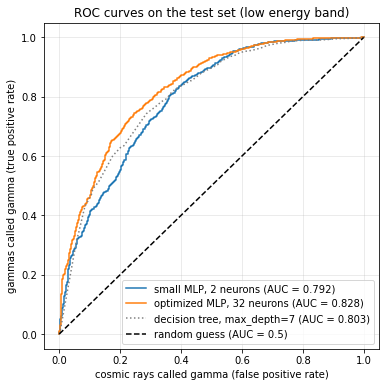

In [74]:
plt.figure(figsize=(6,6))
plt.plot(fpr_small, tpr_small, label=f'small MLP, 2 neurons (AUC = {auc_small:.3f})')
plt.plot(fpr_opt, tpr_opt, label=f'optimized MLP, 32 neurons (AUC = {auc_opt:.3f})')
plt.plot(fpr_tree, tpr_tree, ':', color='gray', label=f'decision tree, max_depth=7 (AUC = {auc_tree:.3f})')
plt.plot([0,1], [0,1], 'k--', label='random guess (AUC = 0.5)')
plt.xlabel('cosmic rays called gamma (false positive rate)')
plt.ylabel('gammas called gamma (true positive rate)')
plt.title('ROC curves on the test set (low energy band)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

The code up in this cell just plots everything.

Additionally, what the graph is saying is that all three models work, and all of the curves are well above the diagonal (random guessing). The optimized MLP is the best, with its AUC = 0.828. That much had been determined before.

The curves also come together at the top right, which shows a sort of collapse, and the decision tree (AUC = 0.803) is the middle. What this shows is that it's better than the 2 neuron MLP, but not as good as the more complex neural network.